# 01 · Actividad | Dataset - Notebook | Individual

Manuel Alejandro Cardona Esquivel
A01795954


## 0. Configuración del entorno

In [1]:
# Librerías estándar y de análisis
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Semilla global
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Estilo de gráficas
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e1", "axes.edgecolor": "#c9c8c2",
                                     "axes.titleweight": "bold", "figure.dpi": 110})
PALETA_FUMADOR = {"no": AZUL, "yes": NARANJA}

print(f"pandas {pd.__version__}")

pandas 3.0.5


## 1. Carga y descripción del dataset

Se usa el dataset público **Medical Cost Personal Dataset** (Kaggle; versión original del libro *Machine Learning with R*,
B. Lantz). El notebook busca primero la copia local en `data/insurance.csv` y, si no existe, la descarga del repositorio público.

In [2]:
RUTA_LOCAL = "../data/insurance.csv"
URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

# Carga
df_raw = pd.read_csv(RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else URL)

print(f"Registros: {df_raw.shape[0]:,} | Variables: {df_raw.shape[1]}")
df_raw.head()

Registros: 1,338 | Variables: 7


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# Tipos de dato detectados por pandas y conteo de no nulos
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


**Diccionario de datos.**

| Variable | Tipo | Significado |
|---|---|---|
| `age` | Numérica entera | Edad del asegurado principal (años). |
| `sex` | Categórica nominal | Sexo del asegurado (`female`, `male`). |
| `bmi` | Numérica continua | Índice de masa corporal (kg/m²). Valores ≥ 30 se consideran obesidad. |
| `children` | Numérica entera (discreta) | Número de hijos / dependientes cubiertos por la póliza. |
| `smoker` | Categórica binaria | Indica si la persona fuma (`yes` / `no`). |
| `region` | Categórica nominal | Región de residencia en EE. UU. (`northeast`, `northwest`, `southeast`, `southwest`). |
| `charges` | Numérica continua — **objetivo** | Costos médicos individuales facturados por el seguro (USD). |

El dataset tiene **1,338 registros y 7 variables**: 3 numéricas predictoras, 3 categóricas y la variable objetivo.

## 2. Análisis exploratorio (EDA)

### 2.1 Estadísticas descriptivas

In [4]:
# Estadísticas de las variables numéricas
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.0,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


In [5]:
# Frecuencia de cada categoría
for col in ["sex", "smoker", "region"]:
    tabla = pd.concat([df_raw[col].value_counts(), df_raw[col].value_counts(normalize=True).mul(100).round(1)],
                      axis=1, keys=["n", "%"])
    print(f"\n— {col} —\n{tabla}")


— sex —
          n     %
sex              
male    676  50.5
female  662  49.5

— smoker —
           n     %
smoker            
no      1064  79.5
yes      274  20.5

— region —
             n     %
region              
southeast  364  27.2
southwest  325  24.3
northwest  325  24.3
northeast  324  24.2


**Lectura.** La edad va de 18 a 64 años (media ≈ 39), el IMC promedio es ≈ 30.7, es decir, la persona media del
dataset está en el umbral de obesidad. `sex` y `region` están balanceadas, pero **solo ~20 % de los asegurados fuma**:
es una clase minoritaria que, como se verá, concentra los costos más altos. En `charges` la media (≈ 13,270 USD) es muy
superior a la mediana (≈ 9,382 USD), señal de una distribución con sesgo a la derecha.

### 2.2 Distribución de la variable objetivo

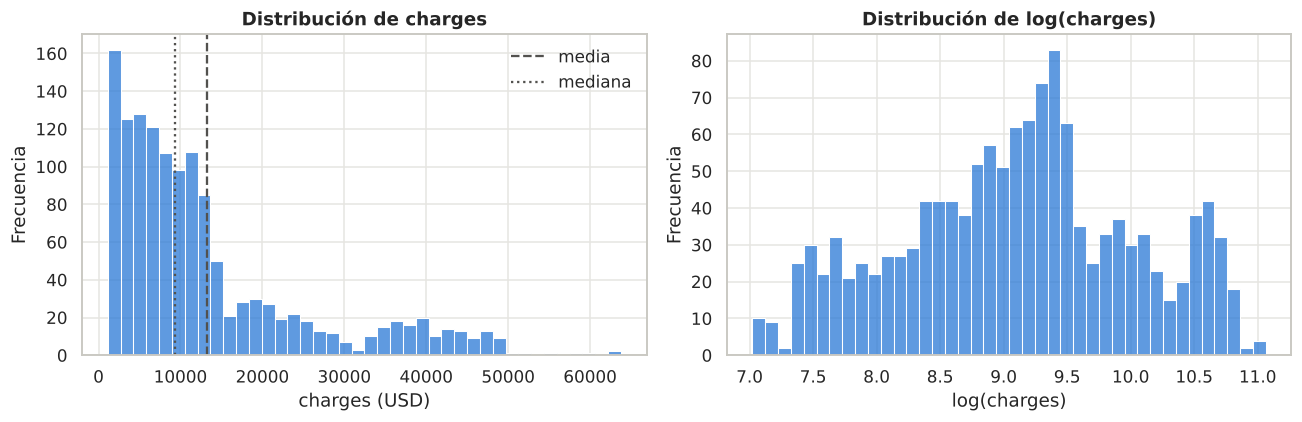

Asimetría charges: 1.52 | log(charges): -0.09


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_raw["charges"], bins=40, color=AZUL, edgecolor="white", ax=axes[0])
axes[0].axvline(df_raw["charges"].mean(), color=GRIS, ls="--", lw=1.5, label="media")
axes[0].axvline(df_raw["charges"].median(), color=GRIS, ls=":", lw=1.5, label="mediana")
axes[0].set(title="Distribución de charges", xlabel="charges (USD)", ylabel="Frecuencia")
axes[0].legend(frameon=False)

sns.histplot(np.log(df_raw["charges"]), bins=40, color=AZUL, edgecolor="white", ax=axes[1])
axes[1].set(title="Distribución de log(charges)", xlabel="log(charges)", ylabel="Frecuencia")
plt.tight_layout(); plt.show()

print(f"Asimetría charges: {df_raw['charges'].skew():.2f} | log(charges): {np.log(df_raw['charges']).skew():.2f}")

**Lectura.** `charges` tiene asimetría positiva fuerte (≈ 1.5) y una larga cola de casos caros. En escala logarítmica
la distribución es mucho más simétrica y aparecen varios "grupos" de costo, lo que sugiere que existen
subpoblaciones (por ejemplo, fumadores y no fumadores) con niveles de costo distintos.

### 2.3 Variables numéricas predictoras

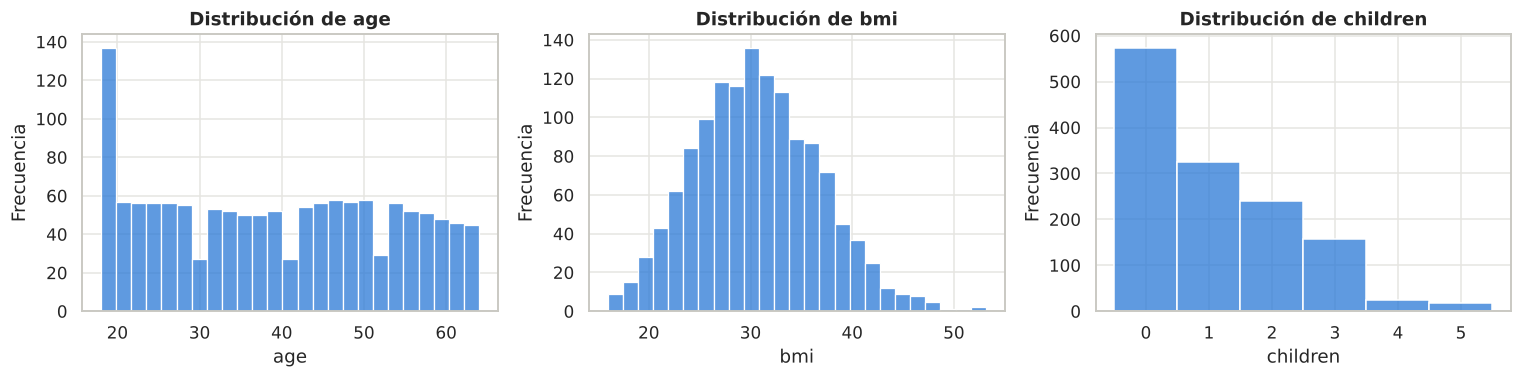

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, ["age", "bmi", "children"]):
    sns.histplot(df_raw[col], bins=25 if col != "children" else 6, discrete=(col == "children"),
                 color=AZUL, edgecolor="white", ax=ax)
    ax.set(title=f"Distribución de {col}", xlabel=col, ylabel="Frecuencia")
plt.tight_layout(); plt.show()

**Lectura.** `age` es casi uniforme salvo un pico en 18–19 años; `bmi` es aproximadamente normal (centro ≈ 30) con
algunos valores altos; `children` es discreta y decreciente (la mayoría no tiene dependientes).

### 2.4 Relación de las variables con el costo

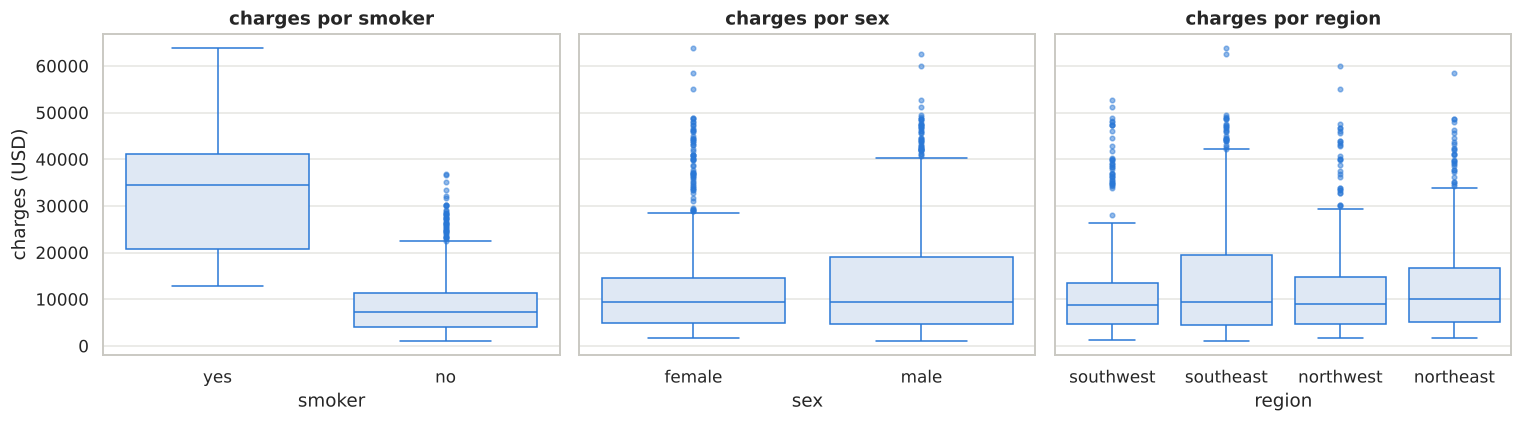

        count   median     mean
smoker                         
no       1064   7345.0   8434.0
yes       274  34456.0  32050.0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, col in zip(axes, ["smoker", "sex", "region"]):
    sns.boxplot(data=df_raw, x=col, y="charges", color="#dbe8f8", linecolor=AZUL,
                flierprops={"marker": "o", "markersize": 3, "markerfacecolor": AZUL, "alpha": .5}, ax=ax)
    ax.set(title=f"charges por {col}", xlabel=col, ylabel="charges (USD)")
plt.tight_layout(); plt.show()

print(df_raw.groupby("smoker")["charges"].agg(["count", "median", "mean"]).round(0))

**Lectura.** Ser fumador es, por mucho, el factor más asociado al costo: la mediana de un fumador (≈ 34,456 USD)
es unas **4.7 veces** la de un no fumador (≈ 7,345 USD). Las diferencias por sexo y región son pequeñas
(la región `southeast` muestra una dispersión algo mayor, coherente con su IMC promedio más alto).

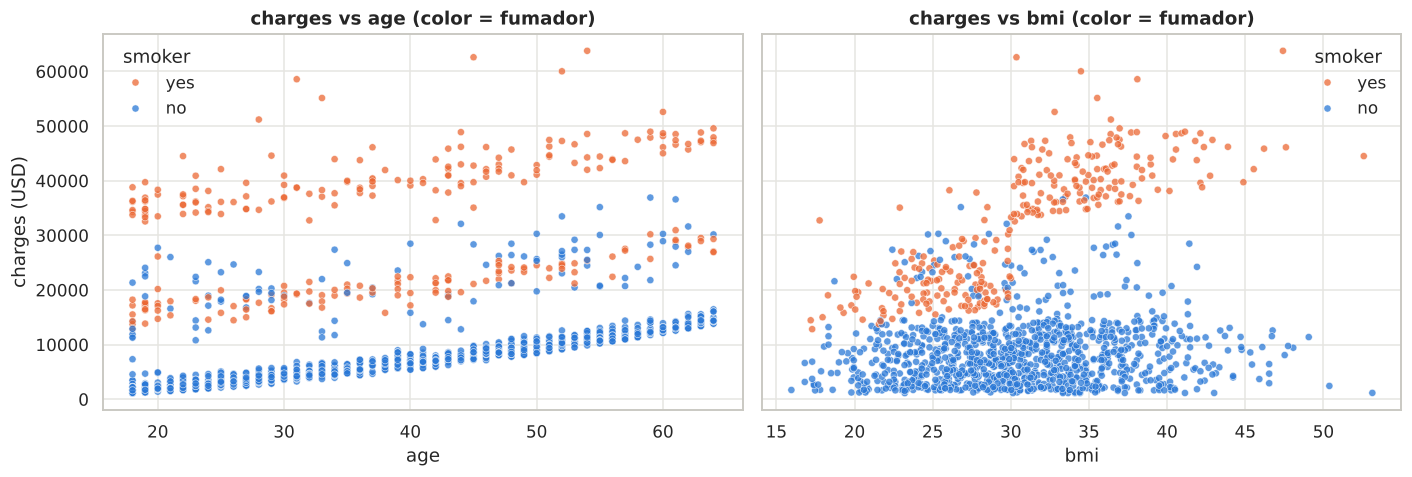

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col in zip(axes, ["age", "bmi"]):
    sns.scatterplot(data=df_raw, x=col, y="charges", hue="smoker", palette=PALETA_FUMADOR,
                    s=22, alpha=.75, edgecolor="white", linewidth=.4, ax=ax)
    ax.set(title=f"charges vs {col} (color = fumador)", xlabel=col, ylabel="charges (USD)")
    ax.legend(title="smoker", frameon=False)
plt.tight_layout(); plt.show()

**Lectura.** Dos hallazgos clave para el modelado:

1. **Edad:** el costo crece de forma casi lineal con la edad y se observan tres "bandas" paralelas
   (no fumadores, fumadores con IMC < 30 y fumadores con IMC ≥ 30).
2. **IMC × fumador (interacción):** para no fumadores el IMC casi no mueve el costo, mientras que en fumadores
   el costo **salta** al cruzar IMC ≈ 30. Un modelo lineal sin términos de interacción no puede capturar este
   efecto, lo que anticipa una limitación del baseline.

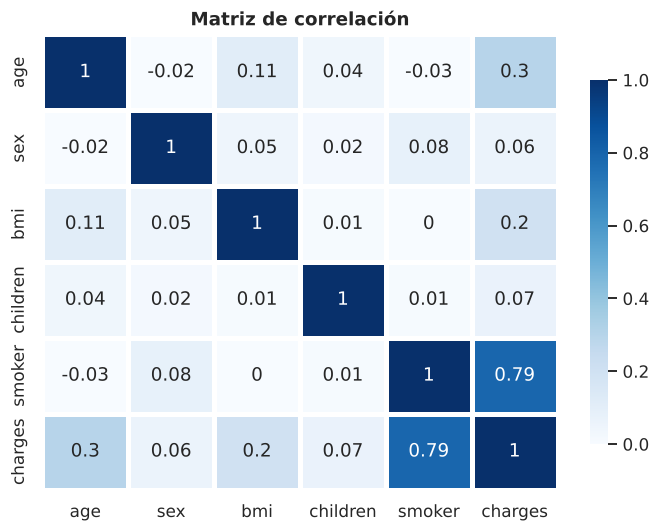

In [10]:
# Correlación de Pearson con las categóricas binarias codificadas (1 = yes / male)
corr_df = df_raw.assign(smoker=(df_raw["smoker"] == "yes").astype(int),
                        sex=(df_raw["sex"] == "male").astype(int)).drop(columns="region")
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr_df.corr().round(2), annot=True, cmap="Blues", vmin=0, vmax=1, linewidths=2, linecolor="white",
            cbar_kws={"shrink": .8})
plt.title("Matriz de correlación"); plt.tight_layout(); plt.show()

**Lectura.** `smoker` tiene la correlación más alta con `charges` (≈ 0.79), seguida de `age` (≈ 0.30) y `bmi` (≈ 0.20).
`sex` y `children` están casi descorrelacionadas con el costo. Entre predictoras no hay correlaciones fuertes,
por lo que no hay problema de multicolinealidad para un modelo lineal.

## 3. Limpieza de datos

Se revisan cuatro tipos de problemas de calidad: **valores faltantes, duplicados, tipos incorrectos y outliers**.
Toda la limpieza se hace sobre una copia (`df`) para conservar los datos originales.

In [11]:
df = df_raw.copy()

# 3.1 Valores faltantes (incluye cadenas vacías disfrazadas de dato)
faltantes = df.isna().sum()
vacios = sum(int(df[c].astype(str).str.strip().eq("").sum()) for c in ["sex", "smoker", "region"])
print("Nulos por columna:\n", faltantes.to_string())
print("Total de nulos:", int(faltantes.sum()), "| Cadenas vacías:", vacios)

Nulos por columna:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
Total de nulos: 0 | Cadenas vacías: 0


**Decisión 3.1 — Faltantes.** No hay valores nulos ni cadenas vacías. No se imputa nada aquí; aun así, el
*pipeline* de entrenamiento queda preparado para que un dato faltante futuro no rompa el flujo
(eso se aborda formalmente en la versión con *script* de la siguiente actividad).

In [12]:
# 3.2 Duplicados exactos
dups = df[df.duplicated(keep=False)]
print(f"Filas duplicadas (exactas): {df.duplicated().sum()}")
display(dups)

df = df.drop_duplicates().reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(df):,}")

Filas duplicadas (exactas): 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Registros tras eliminar duplicados: 1,337


**Decisión 3.2 — Duplicados.** Hay **1 registro duplicado** (mismas 7 columnas, incluido el costo con 4 decimales).
Sin un identificador de asegurado no se puede confirmar si son dos personas idénticas, pero la coincidencia exacta del
costo hace muy probable un error de captura. Se **elimina** la copia para que no aparezca a la vez en entrenamiento
y prueba (fuga de información). Quedan **1,337 registros**.

In [13]:
# 3.3 Tipos de dato y valores de dominio
for col in ["sex", "smoker", "region"]:
    df[col] = df[col].str.strip().str.lower().astype("category")   # normaliza texto y tipifica como categoría
print(df.dtypes)
print("\nCategorías:", {c: list(df[c].cat.categories) for c in ["sex", "smoker", "region"]})

# Validación de rangos plausibles
assert df["age"].between(18, 100).all(), "Edad fuera de rango"
assert df["bmi"].between(10, 70).all(), "IMC fuera de rango"
assert (df["children"] >= 0).all() and (df["charges"] > 0).all(), "Valores negativos"
print("\nRangos válidos ✔")

age            int64
sex         category
bmi          float64
children       int64
smoker      category
region      category
charges      float64
dtype: object

Categorías: {'sex': ['female', 'male'], 'smoker': ['no', 'yes'], 'region': ['northeast', 'northwest', 'southeast', 'southwest']}

Rangos válidos ✔


**Decisión 3.3 — Tipos.** Las columnas de texto se normalizan (minúsculas, sin espacios) y se convierten a `category`
para que el tipo refleje su naturaleza nominal. Las numéricas ya tienen el tipo correcto (`int`/`float`) y todos los
valores están en rangos plausibles (edad 18–64, IMC 16–53, costos positivos).

In [14]:
# 3.4 Outliers con el criterio de Tukey (1.5 × IQR)
def outliers_iqr(serie):
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

resumen = pd.DataFrame({col: {"n_outliers": int(outliers_iqr(df[col]).sum()),
                              "%": round(outliers_iqr(df[col]).mean() * 100, 1)}
                        for col in ["age", "bmi", "children", "charges"]}).T
display(resumen)

out_ch = outliers_iqr(df["charges"])
print(f"Outliers de charges que son fumadores: {(df.loc[out_ch, 'smoker'] == 'yes').mean():.0%}")
print(f"IMC de los outliers de bmi: {sorted(df.loc[outliers_iqr(df['bmi']), 'bmi'].tolist())}")

,n_outliers,%
age,0.0,0.0
bmi,9.0,0.7
children,0.0,0.0
charges,139.0,10.4


Outliers de charges que son fumadores: 98%
IMC de los outliers de bmi: [47.41, 47.52, 47.6, 47.74, 48.07, 49.06, 50.38, 52.58, 53.13]


**Decisión 3.4 — Outliers.** Se detectan 139 outliers en `charges` (~10 %) y 9 en `bmi`:

* En `charges`, prácticamente todos los casos atípicos son **fumadores**: no son errores, son precisamente la
  subpoblación de alto costo que el modelo debe aprender. Eliminarlos sesgaría el modelo a subestimar a los clientes
  más caros, que en un contexto de aseguradora son los más importantes. **Se conservan.**
* En `bmi`, los valores (47–53) son altos pero fisiológicamente posibles (obesidad mórbida). **Se conservan.**

No se transforma la variable objetivo en el baseline para mantenerlo simple e interpretable en USD; la escala
logarítmica queda como mejora candidata.

In [15]:
# Resumen del dataset limpio
print(f"Dataset limpio: {df.shape[0]:,} registros × {df.shape[1]} variables")
df.describe(include="all").T

Dataset limpio: 1,337 registros × 7 variables


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1337.0,NaN,NaN,NaN,39.222139,14.044333,18.0,27.0,39.0,51.0,64.0
sex,1337,2,male,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1337.0,NaN,NaN,NaN,30.663452,6.100468,15.96,26.29,30.4,34.7,53.13
children,1337.0,NaN,NaN,NaN,1.095737,1.205571,0.0,0.0,1.0,2.0,5.0
smoker,1337,2,no,1063,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1337,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1337.0,NaN,NaN,NaN,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801
